In [1]:
from typing import TypedDict,Literal,List
from pydantic import BaseModel,Field
import time
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_core.prompts import HumanMessagePromptTemplate,SystemMessagePromptTemplate,ChatPromptTemplate
from langchain_core.documents import Document
from langgraph.graph import START,StateGraph,END,MessagesState
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_ollama import ChatOllama

C:\Users\PC\AppData\Local\Temp\ipykernel_1696\1539293336.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [2]:
docs=(
    PyPDFLoader(r"C:\Users\PC\Downloads\Product_and_Pricing.pdf").load()
    +PyPDFLoader(r"C:\Users\PC\Downloads\Company_Policies.pdf").load()
    +PyPDFLoader(r"C:\Users\PC\Downloads\Company_Profile.pdf").load()
    
)

In [4]:
llm=ChatOllama(model='qwen2.5:3b',temperature=0)


In [5]:
chunks=RecursiveCharacterTextSplitter(chunk_size=600,chunk_overlap=150).split_documents(docs)

embedding=HuggingFaceEmbeddings(model_name='all-MiniLM-L6-v2')

vectore_store=FAISS.from_documents(documents=chunks,embedding=embedding)


C:\Users\PC\AppData\Local\Temp\ipykernel_1696\2236220499.py:3: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  embedding=HuggingFaceEmbeddings(model_name='all-MiniLM-L6-v2')


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [6]:
retriver=vectore_store.as_retriever(
    search_type='similarity',
    search_kwargs={'k':4}
)



In [7]:
# build a pydantinc model that deside when to retrive or not?
class Retriverdiccision(BaseModel):
    shuold_retrive:bool=Field(
        ...,
        description='True if extranal document are needed to answer realibly else Flase'

    )





In [8]:
decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

In [9]:
should_retrive_llm=llm.with_structured_output(Retriverdiccision)

In [10]:
# GRAPH STATE
class state(TypedDict):
    question:str
    nedd_retrival:bool
    docs:List[Document]
    retrival_docs:List[Document]
    answer:str

In [11]:
def dicide_retrival(state:state):
    decition:Retriverdiccision=should_retrive_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"]))
    return {"nedd_retrival":decition.shuold_retrive}



In [12]:
direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer the question using only your general knowledge.\n"
            "Do NOT assume access to external documents.\n"
            "If you are unsure or the answer requires specific sources, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)

In [13]:
def genrate_direct(state:state):
    out=llm.invoke(direct_generation_prompt.format_messages(question=state['question']))
    return {
        'answer':out.content
    }

In [14]:
def retrive(state:state):
    return {'docs':retriver.invoke(state['question'])}


In [15]:
class relevancedicition(BaseModel):
    is_retrival:bool=Field(
        ...,
        description='True if documnet heplps answer the question else False.'
        
    )

In [16]:
is_relevant_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are judging document relevance.\n"
            "Return JSON that matches this schema:\n"
            "{{'is_relevant': boolean}}\n\n"
            "A document is relevant if it contains information useful for answering the question."
        ),
        (
            "human",
            "Question:\n{question}\n\nDocument:\n{document}"
        ),
    ]
)

In [21]:
relevance_llm=llm.with_structured_output(relevancedicition)




In [22]:
def is_relavant(state: state):
    relavant_docs: List[Document] = []

    for doc in state['docs']:
        decition: relevancedicition = relevance_llm.invoke(
            is_relevant_prompt.format_messages(
                question=state['question'], 
                document=doc.page_content
            )
        )

        # FIX: Changed 'is_relavant' to 'is_relevant'
        if decition.is_relevant: 
            relavant_docs.append(doc)

    return {'retrival_docs': relavant_docs}


In [23]:
def rought_after_diciton(state:state)->Literal['genrate_direct','retrive']:

    if state['nedd_retrival']:
        return 'retrive'
    return 'genrate_direct'

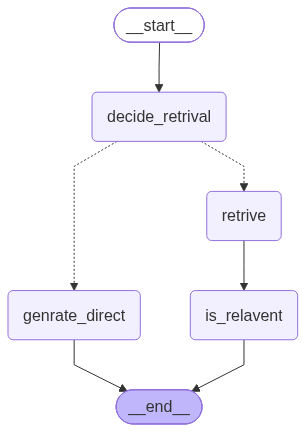

In [24]:
g=StateGraph(state)
g.add_node('decide_retrival',dicide_retrival)
g.add_node('genrate_direct',genrate_direct)
g.add_node('retrive',retrive)
g.add_node('is_relavent',is_relavant)

g.add_edge(START,'decide_retrival')
g.add_conditional_edges(
    'decide_retrival',
    rought_after_diciton,
    {
        'genrate_direct':'genrate_direct',
        'retrive':'retrive'
    }
)

g.add_edge('genrate_direct',END)
g.add_edge('retrive','is_relavent')
g.add_edge('is_relavent',END)

app=g.compile()
app

In [25]:
result=app.invoke({'question':'tell me about nexa ai?','nedd_retrival':False,'docs':[],'answer':''})

print(result['answer'])

AttributeError: 'relevancedicition' object has no attribute 'is_relevant'